# Valuation FII: preço justo por fluxo de caixa descontado para todos os FIIs da B3

**Pergunta:** quais fundos imobiliários negociam abaixo de uma faixa conservadora de preço justo, depois de tratar os erros das fontes de dados?

Este notebook percorre o pipeline do projeto: carga e qualidade dos dados, o modelo FCD validado contra a planilha original, a sensibilidade de todo o universo e a robustez do ranking.

> Material didático. Nenhum resultado aqui é recomendação de compra ou de venda.

In [1]:
import sys, json, sqlite3
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))
from valuation_fii import fcd
from valuation_fii.carga import carregar_fundos, carregar_config
from valuation_fii.pipeline import avaliar, taxa_basica
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
AZUL, LARANJA, CINZA = '#2F5D9E', '#D2601A', '#9AA3AD'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25})
fundos, cfg = carregar_fundos(), carregar_config()
print(cfg['meta']['retrato_em'], '·', len(fundos), 'fundos negociados na B3')

2026-11-10 · 501 fundos negociados na B3


## 1. Dados e qualidade

A planilha de origem junta cinco fontes: Fundamentus (lista e indicadores), Status Invest (segmento, FIAGRO/FI-INFRA, rendimentos), Funds Explorer (segmento ANBIMA), Investidor10 (listas de categoria) e GOOGLEFINANCE (preço). Cada fonte tem erros próprios, então o pipeline separa três níveis de problema:

| Regra | Efeito |
|---|---|
| **Exclusão** | fundo encerrado, sem dados ou sem rendimento em 2026 → fora de tudo |
| **Suspeito** | sem rendimento, sem preço, rendimento mensal > 4% do preço ou liquidez > R$ 500 mi/dia → fora do cálculo |
| **Conferência** | rendimento ou DY divergentes da Status Invest, DY irreal, P/VP > 1,5 → calculado, mas fora do ranking |

In [2]:
con = sqlite3.connect(RAIZ / 'data/processed/valuation_fii.db')
anom = pd.read_sql('SELECT regra, COUNT(*) AS fundos FROM anomalias GROUP BY regra ORDER BY fundos DESC', con)
anom

,regra,fundos
0,conferencia,105
1,exclusao,63
2,suspeito,31


Alguns exemplos reais de erro nas fontes, tirados do próprio retrato:

In [3]:
ex = fundos.loc[['PRTS11', 'JCIN11', 'MXRF11'], ['segmento_fundamentus', 'segmento_anbima', 'cotacao_fundamentus', 'ultimo_rendimento', 'liquidez_diaria', 'motivo_exclusao']]
ex

,segmento_fundamentus,segmento_anbima,cotacao_fundamentus,ultimo_rendimento,liquidez_diaria,motivo_exclusao
ticker,,,,,,
PRTS11,SHOPPINGS,Híbrido,"18,066.2900",0.0500,"4,376,528,441.0000",Sem rendimentos em 2026
JCIN11,FUNDO DE FUNDOS,Shoppings,148.9000,"7,082.9400","9,973,769.0000",
MXRF11,PAPÉIS,Logística,8.6400,0.1000,"29,058,874.0000",


- **PRTS11**: cotação de R$ 18 mil e liquidez de R$ 4,4 bilhões/dia na Fundamentus, valores impossíveis para o fundo (que também está sem rendimentos em 2026 e sai da análise).
- **JCIN11**: último rendimento de R$ 7.082,94 por cota para uma cota de R$ 148,90, um erro de digitação na fonte. O pipeline usa o rendimento normalizado (mediana dos últimos pagamentos).
- **MXRF11**: o segmento ANBIMA do Funds Explorer diz Logística, mas o fundo é de papel (CRIs). Por isso a regra de classificação não usa a ANBIMA para fundos que a Status Invest classifica como Papéis ou Fundo de Fundos.

A classificação de setor segue esta ordem: setor definido à mão → segmento ANBIMA (só para fundos de tijolo) → segmento da fonte. Fundos listados como FIAGRO ou FI-INFRA em qualquer fonte recebem a categoria de maior prêmio.

### Um erro encontrado no painel original

Ao reescrever o painel em Python e comparar fundo a fundo, a busca de colunas por prefixo do painel pegava a coluna **“Setor predominante (edite para incluir)”**, que é a lista de edição, no lugar de **“Setor predominante”**, o valor de cada fundo. Resultado: 22 fundos recebiam o setor de outro ticker, e os setores definidos à mão eram ignorados.

In [4]:
bug = pd.read_csv(RAIZ / 'data/processed/correcao_setor_predominante.csv', index_col=0)
print(len(bug), 'fundos afetados;', (bug.posicao_com_erro.fillna('') != bug.posicao_correta.fillna('')).sum(), 'mudam de posição na faixa')
bug

22 fundos afetados; 3 mudam de posição na faixa


,setor_com_erro,setor_correto,premio_com_erro,premio_correto,posicao_com_erro,posicao_correta
ticker,,,,,,
ABCP11,LOGÍSTICA,SHOPPING,0.1000,0.0250,dentro,dentro
AFHI11,LOGÍSTICA,PAPEL,0.1000,0.3000,abaixo,dentro
AIEC11,LOGÍSTICA,LAJES,0.1000,0.1500,acima,acima
AJFI11,LOGÍSTICA,SHOPPING,0.1000,0.0250,acima,acima
ALZC11,LAJES,PAPEL,0.1500,0.3000,abaixo,abaixo
ALZR11,LAJES,LOGÍSTICA,0.1500,0.1000,acima,dentro
APTO11,RENDA URBANA,RESIDENCIAL,0.1000,0.2500,abaixo,abaixo
APXM11,LOGÍSTICA,SHOPPING,0.1000,0.0250,NaN,NaN
ARCT11,LOGÍSTICA,HÍBRIDO,0.1000,0.2500,NaN,NaN


## 2. Modelo de fluxo de caixa descontado

Para uma cota com rendimento mensal $d$, horizonte de $n$ anos, taxa de desconto $r$ e CAP rate de saída $c$:

$$VJ = \sum_{t=1}^{n} \frac{12d}{(1+r)^t} + \frac{12d / c}{(1+r)^n}$$

- **Taxa de desconto** = taxa básica × (1 + prêmio de risco do setor ou do fundo, o maior). A taxa básica é a média do Tesouro IPCA+ e do Prefixado mais curtos.
- **Rendimento** = média dos últimos 12 pagamentos menos um desvio padrão da oscilação até a mediana (haircut), para não projetar pagamentos extraordinários.
- **Cenários**: CAP de saída ±0,5 p.p. A **faixa de preço justo** vem da matriz 3×3 de taxas (10,5% / 11% / 11,5%, cada uma ajustada pelo prêmio) × CAP.

O modelo foi validado contra a planilha original (TRXF11):

In [5]:
ref = json.loads((RAIZ / 'tests/referencia_planilha.json').read_text())
c = fcd.cenarios(ref['dividendo_mensal'], ref['taxa_desconto'], ref['periodo'], ref['cap'])
pd.DataFrame({'planilha': ref['valor_justo'], 'python': c}).assign(diferenca=lambda x: x.python - x.planilha)

,planilha,python,diferenca
base,100.3856,100.3856,0.0000
otimista,102.6459,102.6459,0.0000
pessimista,98.3633,98.3633,-0.0000


Os testes (`pytest`) também rodam as funções originais do painel em JavaScript sobre o mesmo retrato e conferem, para os 501 fundos, setor, exclusões, faixa de preço justo, posição e conferência. Python e painel batem em todos.

## 3. Sensibilidade de todos os fundos

In [6]:
val = avaliar(fundos, cfg)
print(f"Taxa básica: {taxa_basica(cfg['tesouro']):.2%}")
pos = val.posicao.value_counts().reindex(['abaixo', 'dentro', 'acima'])
pos.to_frame('fundos')

Taxa básica: 11.53%


,fundos
posicao,
abaixo,239
dentro,40
acima,128


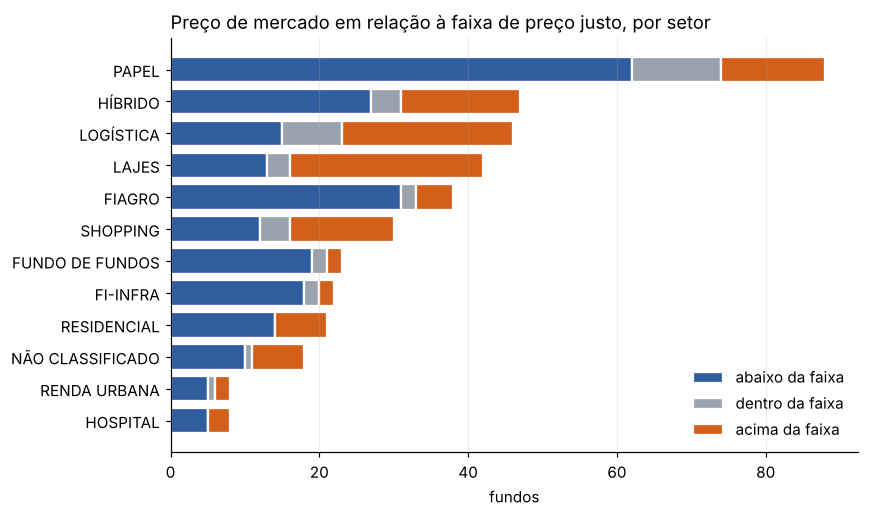

In [7]:
tab = (val.dropna(subset=['posicao']).groupby('setor').posicao.value_counts().unstack(fill_value=0)
       .reindex(columns=['abaixo', 'dentro', 'acima']).assign(total=lambda x: x.sum(axis=1)).sort_values('total'))
tab = tab[tab.total >= 8]
fig, ax = plt.subplots(figsize=(8, 4.8))
esq = np.zeros(len(tab))
for col, cor in [('abaixo', AZUL), ('dentro', CINZA), ('acima', LARANJA)]:
    ax.barh(tab.index, tab[col], left=esq, color=cor, label=f'{col} da faixa', edgecolor='white', linewidth=1.5)
    esq += tab[col].values
ax.set_xlabel('fundos'); ax.set_title('Preço de mercado em relação à faixa de preço justo, por setor', loc='left')
ax.legend(frameon=False, loc='lower right'); ax.grid(axis='y', visible=False); plt.tight_layout()

Fundos de papel e FIAGROs aparecem muito abaixo da faixa. Isso não é necessariamente oportunidade: o modelo projeta rendimentos constantes, e em fundos de crédito o rendimento acompanha o CDI e o risco de inadimplência, que um FCD de renda fixa não captura. É a principal limitação do modelo para esses setores.

In [8]:
cols = ['setor', 'preco', 'rendimento_usado', 'faixa_min', 'faixa_max', 'desconto', 'pvp', 'liquidez_diaria', 'saude']
top = val[val.no_ranking & (val.liquidez_diaria >= 1e6)].sort_values('rank_oportunidade')[cols].head(15)
top.style.format({'preco': 'R$ {:.2f}', 'rendimento_usado': '{:.3f}', 'faixa_min': 'R$ {:.2f}', 'faixa_max': 'R$ {:.2f}',
                  'desconto': '{:+.1%}', 'pvp': '{:.2f}', 'liquidez_diaria': '{:,.0f}'})

,setor,preco,rendimento_usado,faixa_min,faixa_max,desconto,pvp,liquidez_diaria,saude
ticker,,,,,,,,,
OUJP11,PAPEL,R$ 63.33,1.139,R$ 104.42,R$ 116.98,+64.9%,0.63,"1,036,628",ok
TRXF11,HÍBRIDO,R$ 59.00,0.983,R$ 93.08,R$ 104.16,+57.8%,0.67,"37,327,857",ok
HABT11,PAPEL,R$ 61.85,0.935,R$ 85.74,R$ 96.05,+38.6%,0.65,"1,197,038",ok
CPSH11,SHOPPING,R$ 9.25,0.114,R$ 12.54,R$ 13.95,+35.6%,0.83,"2,845,526",ok
CPLG11,LOGÍSTICA,R$ 11.00,0.142,R$ 14.82,R$ 16.52,+34.7%,1.04,"1,783,942",ok
PSEC11,FUNDO DE FUNDOS,R$ 44.38,0.585,R$ 59.06,R$ 65.92,+33.1%,0.61,"3,143,013",ok
ITRI11,SHOPPING,R$ 68.89,0.831,R$ 91.32,R$ 101.57,+32.6%,0.75,"1,402,557",ok
MCRE11,PAPEL,R$ 7.14,0.103,R$ 9.44,R$ 10.58,+32.3%,0.69,"4,576,388",ok
GTWR11,LAJES,R$ 76.78,0.900,R$ 98.87,R$ 110.72,+28.8%,0.74,"1,101,762",ok


## 4. Robustez do ranking

Um ranking que muda muito com pequenas mudanças de premissa não serve para decisão. Abaixo, quantos dos 15 primeiros fundos líquidos continuam no top 15 quando mudam a taxa base da matriz e o haircut.

In [9]:
from valuation_fii.risco import RISCO_PADRAO
def top15(**kw):
    v = avaliar(fundos, cfg, **kw)
    return set(v[v.no_ranking & (v.liquidez_diaria >= 1e6)].sort_values('rank_oportunidade').head(15).index)
base = top15()
cenarios = {'taxa base 10%': dict(taxa_sens=0.10), 'taxa base 12%': dict(taxa_sens=0.12),
            'sem haircut': dict(risco={**RISCO_PADRAO, 'hcOn': False}),
            'haircut de 2 desvios': dict(risco={**RISCO_PADRAO, 'hcK': 2.0})}
rob = pd.DataFrame({k: {'continuam no top 15': len(base & top15(**v))} for k, v in cenarios.items()}).T
rob

,continuam no top 15
taxa base 10%,15
taxa base 12%,15
sem haircut,14
haircut de 2 desvios,15


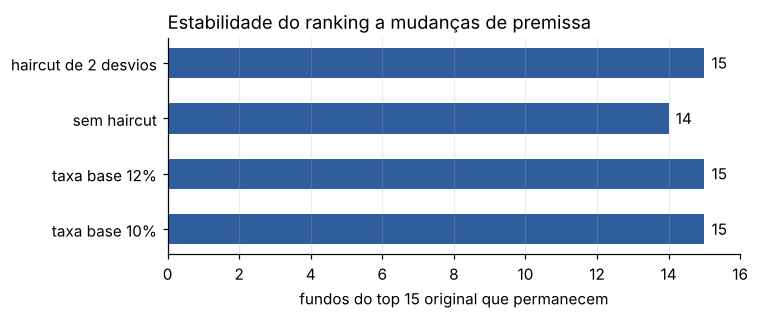

In [10]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(rob.index, rob['continuam no top 15'], color=AZUL, height=.55)
for i, v in enumerate(rob['continuam no top 15']): ax.text(v + .2, i, str(v), va='center')
ax.set_xlim(0, 16); ax.set_xlabel('fundos do top 15 original que permanecem'); ax.grid(axis='y', visible=False)
ax.set_title('Estabilidade do ranking a mudanças de premissa', loc='left'); plt.tight_layout()

## 5. Limitações

- **Rendimento constante:** o FCD supõe que o rendimento atual se mantém por todo o horizonte. Para fundos de papel, que dependem de CDI e IPCA, essa hipótese é fraca.
- **Prêmios de risco definidos por julgamento:** os prêmios por setor são premissas do autor, não estimados a partir de dados de mercado.
- **Retrato único:** os números são de 10/11/2026. Preços e rendimentos mudam todo dia.
- **Saúde dos fundos:** a avaliação de vacância e inadimplência dos relatórios gerenciais foi feita para 73 fundos (P/VP < 0,8 e liquidez ≥ R$ 1 mi), com apoio de IA na leitura dos relatórios.

**Próximos passos:** coleta automatizada direto das fontes, histórico diário de preços para backtest do ranking (os fundos “abaixo da faixa” performaram melhor depois?), e prêmios de risco estimados por spread de mercado.